# Customer Churn Prediction

The full process, in the order it was done. `src/train.py` repeats only the final choices.

1. Explore the data
2. Split train / test (test is used once, at the end)
3. Baseline: all 19 features
4. Log tenure
5. Feature selection
6. Tune models
7. Pick the decision threshold
8. Final test

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_curve, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, TunedThresholdClassifierCV,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent  # notebook lives in notebooks/

# Chart style
BLUE, ORANGE, TEXT_2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.labelcolor": TEXT_2, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
})

## 1. Explore the data

In [2]:
df = pd.read_csv(ROOT / "data" / "customer_churn.csv")
y = (df["churn"] == "Yes").astype(int)  # Yes = 1, No = 0
X = df.drop(columns=["churn", "customer_id"])  # customer_id is just an ID

print(df.shape, f"| churn rate {y.mean():.1%} | missing values {df.isna().sum().sum()}")

(10000, 21) | churn rate 28.2% | missing values 0


Always guessing "no churn" already gives 72% accuracy, so accuracy alone is misleading. We use **ROC AUC** to compare models.

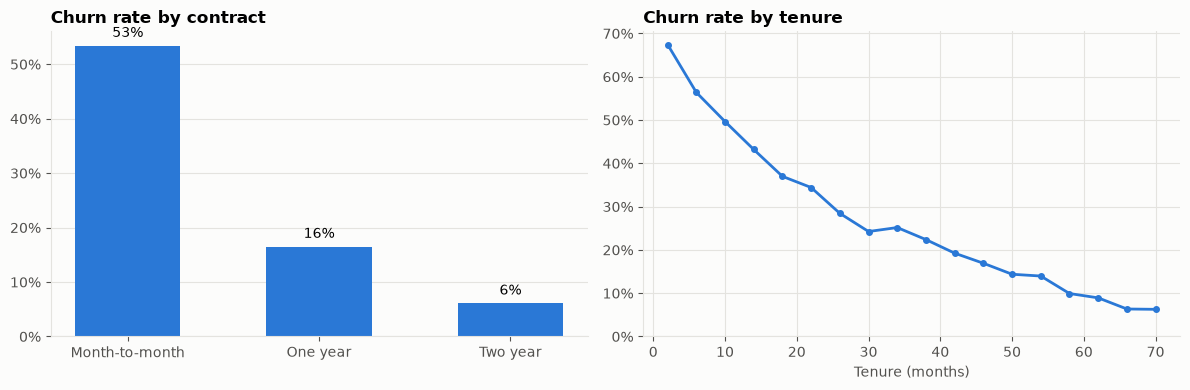

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Churn rate by contract
rate = y.groupby(df["contract"]).mean().reindex(["Month-to-month", "One year", "Two year"])
bars = ax1.bar(rate.index, rate.values, color=BLUE, width=0.55)
ax1.bar_label(bars, labels=[f"{v:.0%}" for v in rate.values], padding=4)
ax1.set_title("Churn rate by contract")
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.grid(axis="x", visible=False)

# Churn rate by tenure (4-month bins)
bins = np.arange(0, 76, 4)
tenure_rate = y.groupby(pd.cut(df["tenure"], bins, right=False), observed=True).mean()
ax2.plot([b.left + 2 for b in tenure_rate.index], tenure_rate.values, color=BLUE, linewidth=2, marker="o", markersize=4)
ax2.set_title("Churn rate by tenure")
ax2.set_xlabel("Tenure (months)")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.set_ylim(0, None)
plt.tight_layout()

Churn drops fast in the first year, then levels off. A straight line fits that poorly, so step 4 tries `log(tenure)`.

## 2. Split train / test

Every decision below uses 5-fold CV on the train set. The test set is used once, in step 8.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y  # stratify keeps the churn ratio
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)  # same folds for every comparison

## 3. Baseline: all 19 features

A helper builds the preprocessing for any set of columns, so later steps can reuse it.

In [5]:
NUM_COLS = ["senior_citizen", "tenure", "monthly_charges", "total_charges"]

def make_pipeline(cols, model, log_tenure=True):
    num = [c for c in cols if c in NUM_COLS and c != "tenure"]
    cat = [c for c in cols if c not in NUM_COLS]
    tenure_steps = [("imp", SimpleImputer(strategy="mean"))]
    if log_tenure:
        tenure_steps.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
    tenure_steps.append(("sc", StandardScaler()))

    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="mean")), ("sc", StandardScaler())]), num),
        ("tenure", Pipeline(tenure_steps), ["tenure"] if "tenure" in cols else []),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
        ]), cat),
    ], verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("model", model)])

def cv_auc(cols, model=None, log_tenure=True):
    model = model or LogisticRegression(max_iter=1000)
    return cross_val_score(make_pipeline(cols, model, log_tenure), X_train[cols], y_train,
                           cv=cv, scoring="roc_auc").mean()

all_cols = list(X.columns)
print(f"Baseline (19 features, raw tenure): CV ROC AUC {cv_auc(all_cols, log_tenure=False):.4f}")

Baseline (19 features, raw tenure): CV ROC AUC 0.8495


## 4. Log tenure

In [6]:
print(f"19 features, log tenure: CV ROC AUC {cv_auc(all_cols):.4f}")

19 features, log tenure: CV ROC AUC 0.8532


A small but real gain, so log tenure stays.

## 5. Feature selection

Shuffle one feature at a time and see how much CV ROC AUC drops (permutation importance), measured on each validation fold.
Keep features that drop it by at least 0.002; the rest add almost nothing.

Keep: ['contract', 'tenure', 'monthly_charges', 'internet_service', 'payment_method', 'tech_support', 'online_security']


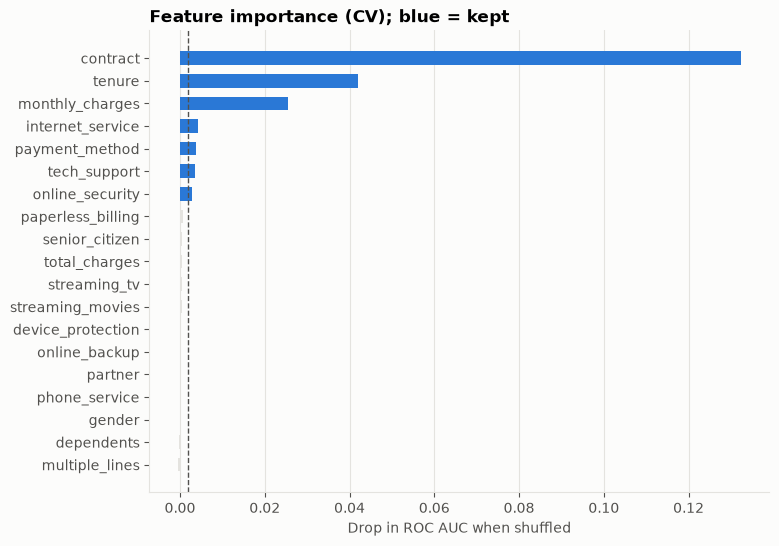

In [7]:
res = cross_validate(make_pipeline(all_cols, LogisticRegression(max_iter=1000)), X_train, y_train,
                     cv=cv, scoring="roc_auc", return_estimator=True, return_indices=True)

# Importance on each validation fold, then average
fold_imp = [
    permutation_importance(est, X_train.iloc[val], y_train.iloc[val],
                           scoring="roc_auc", n_repeats=5, random_state=42).importances_mean
    for est, val in zip(res["estimator"], res["indices"]["test"])
]
importance = pd.DataFrame(fold_imp, columns=all_cols).mean().sort_values()

keep = importance[importance >= 0.002].index.tolist()[::-1]
print("Keep:", keep)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance.index, importance.values, color=[BLUE if c in keep else GRID for c in importance.index], height=0.6)
ax.axvline(0.002, color=TEXT_2, linewidth=1, linestyle="--")
ax.set_title("Feature importance (CV); blue = kept")
ax.set_xlabel("Drop in ROC AUC when shuffled")
ax.grid(axis="y", visible=False);

In [8]:
print(f"All 19 features: CV ROC AUC {cv_auc(all_cols):.4f}")
print(f"{len(keep)} kept features: CV ROC AUC {cv_auc(keep):.4f}")

All 19 features: CV ROC AUC 0.8532
7 kept features: CV ROC AUC 0.8538


Same score with far fewer features, so we keep the smaller set: a simpler model that needs less data.

## 6. Tune models

Tune each model first, then compare tuned scores (fair to every model).

In [9]:
models = {
    "LR": (LogisticRegression(max_iter=1000), {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": ["balanced", None],
    }),
    "RF": (RandomForestClassifier(random_state=42), {
        "model__n_estimators": [300],
        "model__max_depth": [5, 10, 20],
        "model__min_samples_leaf": [1, 5, 20],
        "model__class_weight": ["balanced", None],
    }),
    "HGB": (HistGradientBoostingClassifier(random_state=42), {
        "model__learning_rate": [0.03, 0.1],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__l2_regularization": [0.0, 1.0],
        "model__class_weight": ["balanced", None],
    }),
}

searches = {}
for name, (model, grid) in models.items():
    search = GridSearchCV(make_pipeline(keep, model), grid, cv=5, scoring="roc_auc", n_jobs=-1)
    search.fit(X_train[keep], y_train)
    searches[name] = search
    print(f"{name} CV ROC AUC: {search.best_score_:.4f}  {search.best_params_}")

best_name = max(searches, key=lambda n: searches[n].best_score_)
print(f"Best model: {best_name}")

LR CV ROC AUC: 0.8537  {'model__C': 1, 'model__class_weight': None}
RF CV ROC AUC: 0.8483  {'model__class_weight': None, 'model__max_depth': 10, 'model__min_samples_leaf': 20, 'model__n_estimators': 300}
HGB CV ROC AUC: 0.8495  {'model__class_weight': None, 'model__l2_regularization': 1.0, 'model__learning_rate': 0.03, 'model__max_leaf_nodes': 7}
Best model: LR


## 7. Pick the decision threshold

The default 0.5 isn't always best. Pick the threshold that maximises CV F1 on the train set.

In [10]:
best_model = TunedThresholdClassifierCV(searches[best_name].best_estimator_, scoring="f1", cv=5, n_jobs=-1)
best_model.fit(X_train[keep], y_train)
print(f"Threshold: {best_model.best_threshold_:.3f}  (CV F1: {best_model.best_score_:.4f})")

Threshold: 0.303  (CV F1: 0.6706)


## 8. Final test (once)

In [11]:
y_proba = best_model.predict_proba(X_test[keep])[:, 1]
y_pred = best_model.predict(X_test[keep])

print(f"Test ROC AUC: {roc_auc_score(y_test, y_proba):.4f}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))

Test ROC AUC: 0.8546
Test accuracy: 0.7830
              precision    recall  f1-score   support

           0       0.89      0.80      0.84      1436
           1       0.59      0.75      0.66       564

    accuracy                           0.78      2000
   macro avg       0.74      0.77      0.75      2000
weighted avg       0.81      0.78      0.79      2000



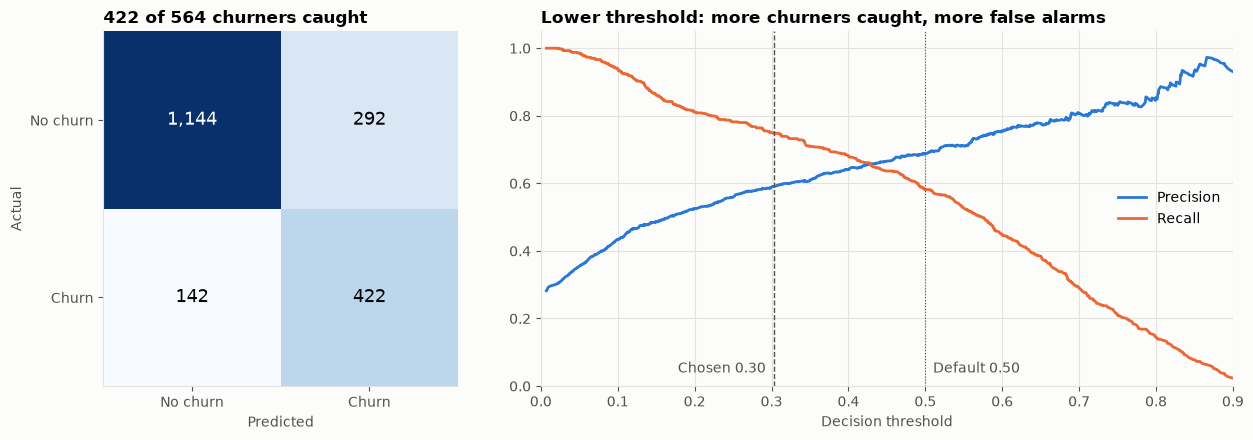

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ax1.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
ax1.set_xticks([0, 1], ["No churn", "Churn"])
ax1.set_yticks([0, 1], ["No churn", "Churn"])
ax1.set_xlabel("Predicted")
ax1.set_ylabel("Actual")
ax1.grid(False)
ax1.set_title(f"{cm[1, 1]} of {cm[1].sum()} churners caught")

# Precision / recall by threshold
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
t = best_model.best_threshold_
ax2.plot(thresholds, precision[:-1], color=BLUE, linewidth=2, label="Precision")
ax2.plot(thresholds, recall[:-1], color=ORANGE, linewidth=2, label="Recall")
ax2.axvline(t, color=TEXT_2, linewidth=1, linestyle="--")
ax2.text(t - 0.01, 0.04, f"Chosen {t:.2f}", color=TEXT_2, ha="right")
ax2.axvline(0.5, color=TEXT_2, linewidth=0.8, linestyle=":")
ax2.text(0.51, 0.04, "Default 0.50", color=TEXT_2)
ax2.legend(frameon=False, loc="center right")
ax2.set_title("Lower threshold: more churners caught, more false alarms")
ax2.set_xlabel("Decision threshold")
ax2.set_xlim(0, 0.9)  # few customers score above 0.9; the curve gets noisy there
ax2.set_ylim(0, 1.05)
plt.tight_layout()